In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [6]:
df = pd.read_csv("/content/Mall_Customers.csv")


In [7]:
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [9]:
print(df.columns.tolist())


['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [10]:
display(df.describe(include="all"))


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


In [11]:
print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [12]:
print(df.duplicated().sum())

0


In [13]:
df = df.drop_duplicates().copy()


In [14]:
df.columns = df.columns.str.strip()


In [15]:
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            mode = df[col].mode()
            if not mode.empty:
                df[col] = df[col].fillna(mode[0])

In [16]:
print(df.isnull().sum())

print("\nDataset shape:", df.shape)

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Dataset shape: (200, 5)


In [17]:
score_column = "Spending Score (1-100)"

if score_column not in df.columns:
    raise ValueError(
        "Spending Score (1-100) column not found. "
        "Check your dataset column names."
    )

def categorize_spending(score):
    if score <= 40:
        return "Low"
    elif score <= 70:
        return "Medium"
    else:
        return "High"

df["Spending_Category"] = df[score_column].apply(
    categorize_spending
)

print("Spending categories created!")

display(df[["Age", "Annual Income (k$)",
            score_column, "Spending_Category"]].head())

Spending categories created!


,Age,Annual Income (k$),Spending Score (1-100),Spending_Category
0,19,15,39,Low
1,21,15,81,High
2,20,16,6,Low
3,23,16,77,High
4,31,17,40,Low


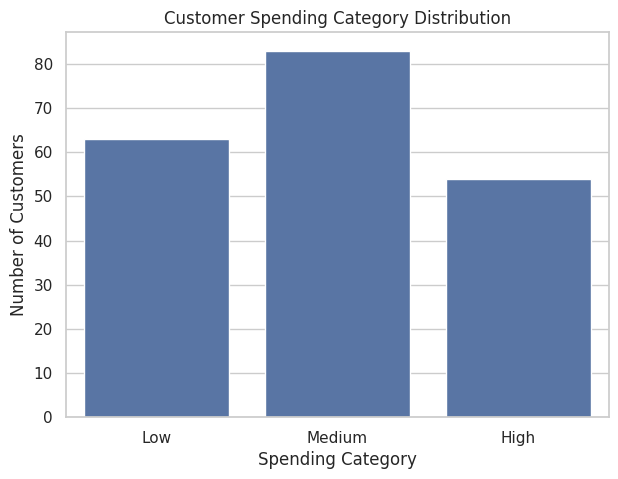

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Spending_Category",
    order=["Low", "Medium", "High"]
)

plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.show()

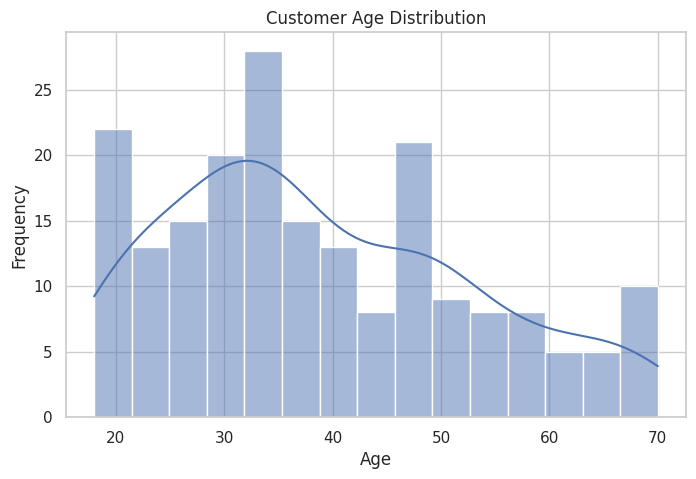

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

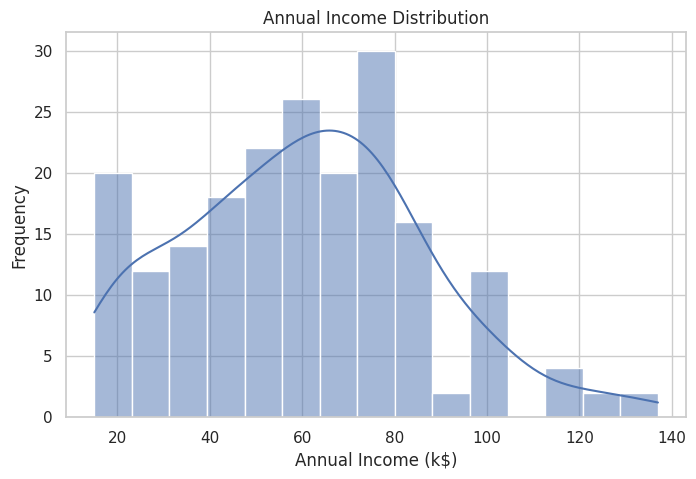

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Annual Income (k$)",
    bins=15,
    kde=True
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Frequency")
plt.show()

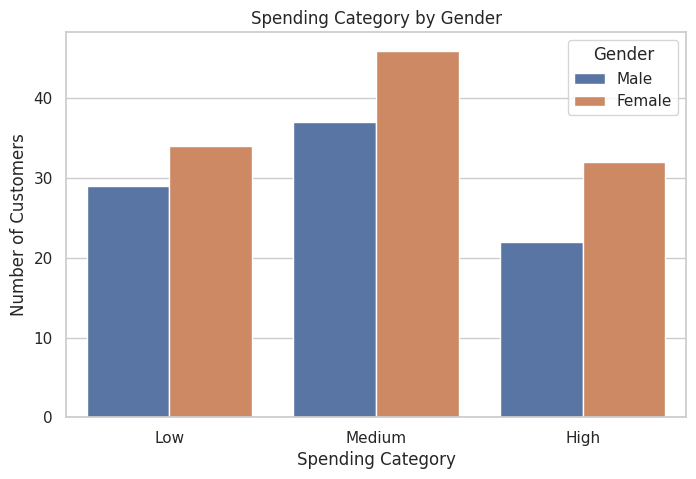

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Spending_Category",
    hue="Gender",
    order=["Low", "Medium", "High"]
)

plt.title("Spending Category by Gender")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.show()

In [22]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 40, 60, 100],
    labels=["Young", "Adult", "Middle Aged", "Senior"]
)

df["Income_Group"] = pd.cut(
    df["Annual Income (k$)"],
    bins=[-np.inf, 40, 70, np.inf],
    labels=["Low Income", "Medium Income", "High Income"]
)

print("Feature engineering completed!")

display(df.head())

Feature engineering completed!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Spending_Category,Age_Group,Income_Group
0,1,Male,19,15,39,Low,Young,Low Income
1,2,Male,21,15,81,High,Young,Low Income
2,3,Female,20,16,6,Low,Young,Low Income
3,4,Female,23,16,77,High,Young,Low Income
4,5,Female,31,17,40,Low,Adult,Low Income


In [23]:
# Target variable
y = df["Spending_Category"]

# Remove target, original score, and customer ID
columns_to_drop = [
    "Spending_Category",
    "Spending Score (1-100)",
    "CustomerID"
]

X = df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

# Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Numerical Features: ['Age', 'Annual Income (k$)']
Categorical Features: ['Gender', 'Age_Group', 'Income_Group']


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (160, 5)
Testing Data: (40, 5)


In [25]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Model Trained!")

Logistic Regression Model Trained!


In [26]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest Model Trained!")

Random Forest Model Trained!


In [27]:
def evaluate_model(name, y_true, y_pred):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
)

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.725,0.7459,0.725,0.7313
1,Random Forest,0.800,0.7953,0.800,0.7946


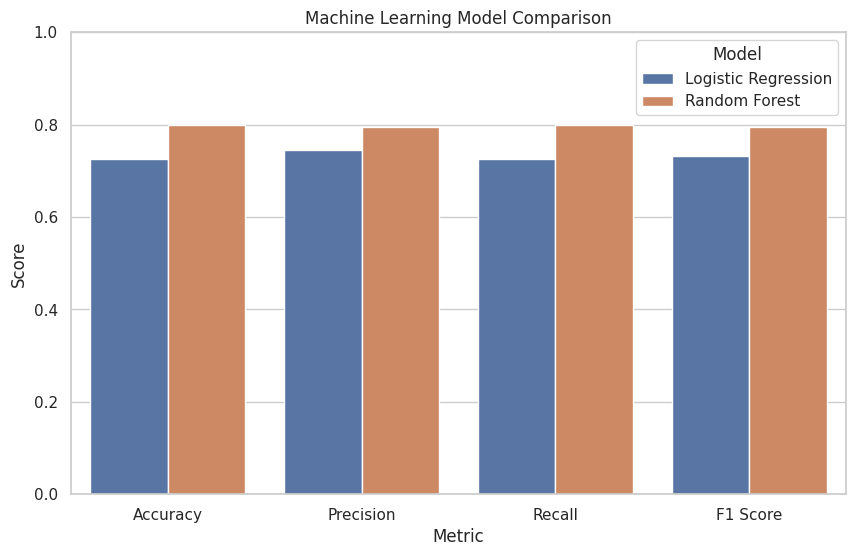

In [28]:
results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Machine Learning Model Comparison")
plt.ylim(0, 1)
plt.show()

Best Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

        High       0.64      0.64      0.64        11
         Low       0.80      0.67      0.73        12
      Medium       0.89      1.00      0.94        17

    accuracy                           0.80        40
   macro avg       0.78      0.77      0.77        40
weighted avg       0.80      0.80      0.79        40



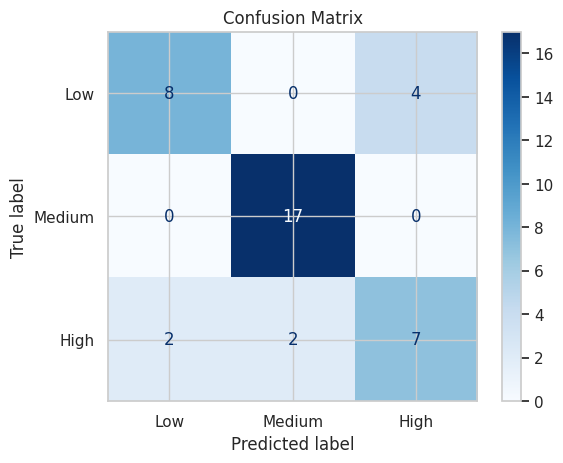

In [29]:
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

if best_model_name == "Random Forest":
    best_model = random_forest_model
    best_predictions = rf_predictions
else:
    best_model = logistic_model
    best_predictions = logistic_predictions

print("Best Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

,Feature,Importance
4,Income_Group,0.307150
3,Age_Group,0.075594
2,Annual Income (k$),0.044143
1,Age,0.023112
0,Gender,-0.071737


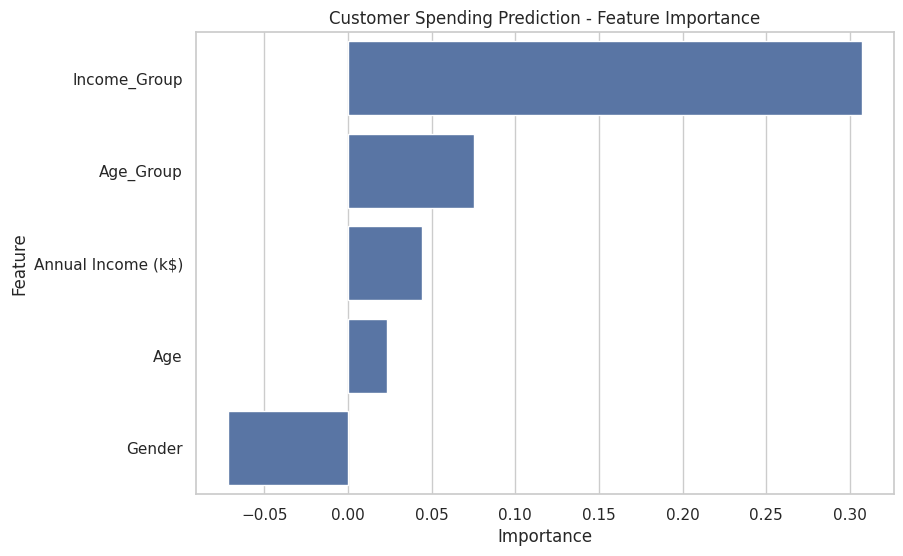

In [30]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1_weighted"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Customer Spending Prediction - Feature Importance")
plt.show()

In [31]:
def predict_customer_spending(age, gender, annual_income):

    customer = pd.DataFrame({
        "Age": [age],
        "Gender": [gender],
        "Annual Income (k$)": [annual_income],
        "Age_Group": pd.cut(
            [age],
            bins=[0, 25, 40, 60, 100],
            labels=["Young", "Adult", "Middle Aged", "Senior"]
        ),
        "Income_Group": pd.cut(
            [annual_income],
            bins=[-np.inf, 40, 70, np.inf],
            labels=["Low Income", "Medium Income", "High Income"]
        )
    })

    # Match the model's expected feature columns
    customer = customer.reindex(columns=X.columns)

    prediction = best_model.predict(customer)

    print("Customer Details:")
    print("Age:", age)
    print("Gender:", gender)
    print("Annual Income:", annual_income)

    print("\nPredicted Spending Category:", prediction[0])

    return prediction[0]


# Example prediction
predict_customer_spending(
    age=25,
    gender="Male",
    annual_income=60
)

Customer Details:
Age: 25
Gender: Male
Annual Income: 60

Predicted Spending Category: Medium


'Medium'

In [32]:
def predict_customer_spending(age, gender, annual_income):

    customer = pd.DataFrame({
        "Age": [age],
        "Gender": [gender],
        "Annual Income (k$)": [annual_income],
        "Age_Group": pd.cut(
            [age],
            bins=[0, 25, 40, 60, 100],
            labels=["Young", "Adult", "Middle Aged", "Senior"]
        ),
        "Income_Group": pd.cut(
            [annual_income],
            bins=[-np.inf, 40, 70, np.inf],
            labels=["Low Income", "Medium Income", "High Income"]
        )
    })

    # Match the model's expected feature columns
    customer = customer.reindex(columns=X.columns)

    prediction = best_model.predict(customer)

    print("Customer Details:")
    print("Age:", age)
    print("Gender:", gender)
    print("Annual Income:", annual_income)

    print("\nPredicted Spending Category:", prediction[0])

    return prediction[0]


# Example prediction
predict_customer_spending(
    age=25,
    gender="Male",
    annual_income=60
)

Customer Details:
Age: 25
Gender: Male
Annual Income: 60

Predicted Spending Category: Medium


'Medium'

In [33]:
print("=" * 50)
print("CUSTOMER SPENDING ANALYSIS - BUSINESS INSIGHTS")
print("=" * 50)

print("\n1. Total Customers:", len(df))

print("\n2. Spending Category Distribution:")
print(df["Spending_Category"].value_counts())

print("\n3. Average Customer Age:",
      round(df["Age"].mean(), 2))

print("\n4. Average Annual Income:",
      round(df["Annual Income (k$)"].mean(), 2))

print("\n5. Most Common Spending Category:",
      df["Spending_Category"].mode()[0])

print("\n6. Most Common Gender:",
      df["Gender"].mode()[0])

print("\n7. Best Performing Model:", best_model_name)

print("\n8. Model Performance:")
display(results_df.round(4))

print("\n9. Most Influential Feature:")
print(importance_df.iloc[0]["Feature"])

print("\n" + "=" * 50)

CUSTOMER SPENDING ANALYSIS - BUSINESS INSIGHTS

1. Total Customers: 200

2. Spending Category Distribution:
Spending_Category
Medium    83
Low       63
High      54
Name: count, dtype: int64

3. Average Customer Age: 38.85

4. Average Annual Income: 60.56

5. Most Common Spending Category: Medium

6. Most Common Gender: Female

7. Best Performing Model: Random Forest

8. Model Performance:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.725,0.7459,0.725,0.7313
1,Random Forest,0.800,0.7953,0.800,0.7946



9. Most Influential Feature:
Income_Group



In [34]:
import joblib

# Save cleaned dataset
df.to_csv("Cleaned_Customer_Data.csv", index=False)

# Save model
joblib.dump(best_model, "Customer_Spending_Model.pkl")

# Save comparison results
results_df.to_csv("Model_Comparison.csv", index=False)

# Save feature importance
importance_df.to_csv("Feature_Importance.csv", index=False)

print("All project files saved successfully!")

All project files saved successfully!


In [35]:
print("FINAL PROJECT SUMMARY")

print("Total Records:", len(df))
print("Total Features:", X.shape[1])
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

print("\nBest Model:", best_model_name)

display(results_df.round(4))

FINAL PROJECT SUMMARY
Total Records: 200
Total Features: 5
Training Records: 160
Testing Records: 40

Missing Values: 0
Duplicate Records: 0

Best Model: Random Forest


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.725,0.7459,0.725,0.7313
1,Random Forest,0.800,0.7953,0.800,0.7946
